[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch40_LabCh40_LoRA_By_Hand.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 40: LoRA and Other Small Adapters** (Part IX: Putting Big Models to Work).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=40](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=40)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch40 - LoRA by hand
## Freeze a whole language model, clip a few thousand numbers onto it, and teach it a new kind of text

This lab goes with **Chapter 40** of *The Why Book of Deep Learning, Part 2*.

Full fine-tuning (Chapter 39) changes every weight, so every task needs its own full copy of the model.
**LoRA** (low-rank adaptation, 2021) freezes the model and trains a small pair of matrices beside some of its
weight matrices. In this lab you write that layer yourself, count what it trains, prove that it changes
nothing until it has learnt something, and measure what it can and cannot do against full fine-tuning.

The model is **TinyGPT** from Chapter 35 (decoder-only, pre-norm, d = 64, 4 heads, 2 blocks, feed-forward 256,
context 64, 39 characters). The lab trains it from nothing on ordinary film reviews (that is the "pretrained
model somebody gave you"), then adapts it to the same kind of reviews written in a simplified **Pig Latin**.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Say what a rank-r change can and cannot do to a layer's output | Step 6 |
| Write a `LoRADense` layer: frozen W, trainable pair, zero start | Step 7 |
| Freeze a model, add adapters, and count trainable and frozen numbers by hand | Step 8 |
| Prove an adapter is a no-op before training, and see what breaks that | Steps 8 and 9 |
| Compare ranks 1, 2, 4, 8 with full fine-tuning on equal terms | Steps 10 to 13 |
| Tell a rank limit from a placement limit | Step 14 |
| Merge an adapter into the weights, and unplug one | Steps 15 and 16 |
| Read the singular values of a weight change | Step 17 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** about four to five minutes on a laptop CPU: Step 5 (pretraining) takes about a minute and a
> half, and Steps 10 to 14 train seven short runs of fifteen to thirty seconds each. No GPU is needed. The only download is
> the IMDB data set that ships with Keras.

> **Honest scale:** this is a miniature. The model has about a hundred thousand weights and is 64 wide, so
> rank 8 is an eighth of the full width. In a model 768 or 4,096 wide the same rank is a far thinner slice,
> and the task here (a new spelling rule) is further from the pretraining text than most real fine-tuning
> tasks are. Read the lab for the mechanism and the shape of the trade, not for the percentages.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 40
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - Two kinds of text

**Text A** is the corpus of Chapter 35: IMDB reviews decoded back to lowercase words (`load_corpus()` is copied
from that lab). **Text B** is made from other reviews by one fixed rule, a simplified Pig Latin: move the
first letter of every word to the end and add `ay`. So `this movie was great` becomes
`histay oviemay asway reatgay`.

Text B uses the same 39 characters as text A, and nearly the same words, but every word is now spelt in a
way the pretrained model has never seen.

> **Predict:** a model trained only on text A reads text B. Will its loss be a little worse than on text A,
> as bad as a blind guess (ln 39 = 3.66), or somewhere between?

In [2]:
ALPHABET = "\n '0123456789abcdefghijklmnopqrstuvwxyz"   # newline, space, apostrophe, digits, letters


def load_corpus(n_reviews=3000):
    """IMDB reviews from keras.datasets, decoded to lowercase text. Returns a list of strings, one per review.
    Only the characters in ALPHABET survive; everything else is dropped."""
    (x_train, _), _ = keras.datasets.imdb.load_data()
    word_index = keras.datasets.imdb.get_word_index()
    id_to_word = {i + 3: w for w, i in word_index.items()}      # ids 0, 1, 2 are pad, start, unknown
    keep = set(ALPHABET) - {"\n"}
    reviews = []
    for ids in x_train[:n_reviews]:
        words = [id_to_word.get(i, "") for i in ids if i >= 3]
        line = " ".join(w for w in words if w and w != "br").lower()
        line = "".join(ch for ch in line if ch in keep)
        reviews.append(" ".join(line.split()))
    return reviews


def pig_latin(text):
    """A simplified Pig Latin: first letter of each word to the end, then 'ay'."""
    return " ".join(w[1:] + w[0] + "ay" for w in text.split(" ") if w)


reviews = load_corpus()
print(f"{len(reviews):,} reviews")
print("text A:", reviews[2700][:76])
print("text B:", pig_latin(reviews[2700])[:76])
assert pig_latin("this movie was great") == "histay oviemay asway reatgay"

3,000 reviews
text A: unfortunately the movie is more concerned with making lame social commentary
text B: nfortunatelyuay hetay oviemay siay oremay oncernedcay ithway akingmay amelay


---
## Step 3 - Ids, splits and fixed validation sets

`encode`, `decode` and `random_windows` are Chapter 35's. The split is by review, so no validation character
is ever trained on:

* **text A:** reviews 0 to 2,399 to pretrain on, reviews 2,400 to 2,699 to validate
* **text B:** reviews 2,700 to 2,949 (in Pig Latin) to adapt on, reviews 2,950 to 2,999 (in Pig Latin) to validate

The adaptation set is a tenth the size of the pretraining set. That is the usual situation: a lot of general
text, a little of your own.

> **Predict:** Pig Latin adds two letters to every word. Roughly what fraction longer is text B than the same
> reviews in plain English, if an English word here averages about four and a half letters plus a space?

In [3]:
V = len(ALPHABET)
char_to_id = {ch: i for i, ch in enumerate(ALPHABET)}
CONTEXT = 64


def encode(text):
    """text -> array of ids. Characters outside ALPHABET are dropped."""
    return np.array([char_to_id[ch] for ch in text.lower() if ch in char_to_id], dtype=np.int32)


def decode(ids):
    """ids -> text."""
    return "".join(ALPHABET[int(i)] for i in ids)


def random_windows(data, n, context=CONTEXT, rng=rng):
    """n windows starting at random places in data. Returns x (n, context) and y (n, context), y = x shifted by one."""
    starts = rng.integers(0, len(data) - context - 1, size=n)
    idx = starts[:, None] + np.arange(context + 1)[None, :]
    w = data[idx]
    return w[:, :-1], w[:, 1:]


A_train = encode("\n".join(reviews[:2400]) + "\n")
A_val = encode("\n".join(reviews[2400:2700]) + "\n")
B_train = encode("\n".join(pig_latin(r) for r in reviews[2700:2950]) + "\n")
B_val = encode("\n".join(pig_latin(r) for r in reviews[2950:]) + "\n")
plain_B = sum(len(r) + 1 for r in reviews[2700:2950])
print(f"V = {V}")
print(f"text A: {len(A_train):,} characters to pretrain on, {len(A_val):,} to validate")
print(f"text B: {len(B_train):,} characters to adapt on,    {len(B_val):,} to validate")
print(f"the same 250 reviews in plain English: {plain_B:,} characters, so Pig Latin is {len(B_train) / plain_B - 1:.0%} longer")

xa_val, ya_val = random_windows(A_val, 1000, rng=np.random.default_rng(1))
xb_val, yb_val = random_windows(B_val, 1000, rng=np.random.default_rng(2))
print("fixed validation sets:", xa_val.shape, "of text A,", xb_val.shape, "of text B")

V = 39
text A: 3,077,560 characters to pretrain on, 423,041 to validate
text B: 454,454 characters to adapt on,    83,892 to validate
the same 250 reviews in plain English: 332,112 characters, so Pig Latin is 37% longer
fixed validation sets: (1000, 64) of text A, (1000, 64) of text B


---
## Step 4 - TinyGPT, with attention you can open

Chapter 35 built TinyGPT with `layers.MultiHeadAttention`. That layer keeps its four projection matrices
(query, key, value, output) inside itself, where we cannot swap them. LoRA needs to get at them, so here the
same attention is built from four plain `Dense(64)` layers and one small layer with **no weights**,
`AttentionCore`, that does what is left: split into heads, score, mask the future, softmax, mix.

Nothing else changes, and the parameter count must come out the same as Chapter 35's: four 64 × 64 matrices
with biases are 4·64² + 4·64 = 16,640 whichever layer holds them.

`build_tinygpt` takes three extra arguments, `rank`, `alpha` and `targets`. With `rank=0` (the default) they
do nothing. Step 8 uses them.

> **Predict:** the total parameter count. (Chapter 35 printed it.) Then: after changing one character at
> position 40, which output positions may move?

In [4]:
class TokenAndPosition(layers.Layer):
    """ids (batch, T) -> vectors (batch, T, d): a token table plus a learnt position table."""

    def __init__(self, vocab_size, context, d, **kwargs):
        super().__init__(**kwargs)
        init = keras.initializers.RandomNormal(stddev=0.02)
        self.token_table = layers.Embedding(vocab_size, d, embeddings_initializer=init, name="token_table")
        self.position_table = layers.Embedding(context, d, embeddings_initializer=init, name="position_table")

    def call(self, ids):
        positions = keras.ops.arange(keras.ops.shape(ids)[1])
        return self.token_table(ids) + self.position_table(positions)


class AttentionCore(layers.Layer):
    """Causal multi-head attention with the projections taken out. No weights.
    [queries, keys, values], each (batch, T, d) -> mixed values (batch, T, d)."""

    def __init__(self, heads, **kwargs):
        super().__init__(**kwargs)
        self.heads = heads

    def call(self, inputs):
        ops = keras.ops
        q, k, v = inputs
        T, d = q.shape[1], q.shape[2]
        head_dim = d // self.heads

        def split(t):                                              # (batch, T, d) -> (batch, heads, T, head_dim)
            return ops.transpose(ops.reshape(t, (-1, T, self.heads, head_dim)), (0, 2, 1, 3))

        q, k, v = split(q), split(k), split(v)
        scores = ops.matmul(q, ops.transpose(k, (0, 1, 3, 2))) / head_dim ** 0.5      # (batch, heads, T, T)
        future = 1.0 - ops.tril(ops.ones((T, T)))                  # 1 where a position would look ahead
        weights = ops.softmax(scores - 1e9 * future, axis=-1)
        mixed = ops.matmul(weights, v)                             # (batch, heads, T, head_dim)
        return ops.reshape(ops.transpose(mixed, (0, 2, 1, 3)), (-1, T, d))


def build_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64, rank=0, alpha=None, targets=("q", "v")):
    """TinyGPT of Chapter 35 with its attention built from Dense layers.
    rank > 0: the layers named in `targets` become LoRADense (Step 7) and every other layer is frozen."""

    def linear(units, name, kind, activation=None):
        if rank > 0 and kind in targets:
            return LoRADense(units, rank, alpha, activation=activation, name=name)
        return layers.Dense(units, activation=activation, name=name)

    ids = layers.Input(shape=(context,), dtype="int32", name="ids")
    x = TokenAndPosition(vocab_size, context, d, name="embed")(ids)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        q = linear(d, f"block{b}_q", "q")(h)
        k = linear(d, f"block{b}_k", "k")(h)
        v = linear(d, f"block{b}_v", "v")(h)
        h = AttentionCore(heads, name=f"block{b}_mix")([q, k, v])
        h = linear(d, f"block{b}_o", "o")(h)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = linear(ff, f"block{b}_ff_wide", "ff_wide", activation="gelu")(h)
        h = linear(d, f"block{b}_ff_narrow", "ff_narrow")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    logits = layers.Dense(vocab_size, kernel_initializer=keras.initializers.RandomNormal(stddev=0.02), name="head")(x)
    model = keras.Model(ids, logits, name="TinyGPT")
    if rank > 0:
        for layer in model.layers:
            if not isinstance(layer, LoRADense):
                layer.trainable = False                            # freeze the base
    return model


def count_weights(weights):
    return int(sum(np.prod(w.shape) for w in weights))


base = build_tinygpt(V)
d, ff = 64, 256
one_block = (4 * d * d + 4 * d) + (d * ff + ff) + (ff * d + d) + 2 * (2 * d)
hand_total = V * d + CONTEXT * d + 2 * one_block + 2 * d + (d * V + V)
print(f"one block: {one_block:,}   hand count: {hand_total:,}   Keras: {base.count_params():,}")
assert base.count_params() == hand_total == 109_223

a = np.array(xa_val[:1]); b = a.copy(); b[0, 40] = (b[0, 40] + 1) % V
moved = np.abs(base.predict_on_batch(a) - base.predict_on_batch(b)).max(axis=-1)[0]
print(f"leak test: largest change at positions 0..39 = {moved[:40].max():.6f}, at 40..63 = {moved[40:].max():.4f}")
assert moved[:40].max() < 1e-5, "the future is leaking into the past"

one block: 49,984   hand count: 109,223   Keras: 109,223


leak test: largest change at positions 0..39 = 0.000000, at 40..63 = 0.1583


### Why we see this

109,223: the same count as Chapter 35's TinyGPT, because moving four matrices out of one layer and into four
moves no weights. The leak test is Chapter 35's too: positions before the changed character do not move, so
our hand-built mask works.

---
## Step 5 - Pretrain on text A

This is the part somebody else normally does for you, on far more text. Chapter 35's recipe (AdamW, warm-up,
cosine decay, clipping at norm 1), cut to 1,500 steps to keep the lab short.

> **Predict:** the loss on text A after pretraining (Chapter 35 reached about 1.5 in 3,000 steps). Then the
> loss of this model on **text B**, which it has never seen: your prediction from Step 2.

> This is the slowest cell: a little over a minute.

In [5]:
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
BATCH, PRE_STEPS = 64, 1500
schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0, warmup_target=3e-3, warmup_steps=100, decay_steps=PRE_STEPS - 100, alpha=0.05)
base.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.01, clipnorm=1.0), loss=loss_fn)
print(f"before training: loss on text A {base.evaluate(xa_val, ya_val, batch_size=250, verbose=0):.3f}   (ln 39 = {np.log(V):.3f})")

t0 = time.time()
x, y = random_windows(A_train, PRE_STEPS * BATCH)
base.fit(x, y, batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
base_A = base.evaluate(xa_val, ya_val, batch_size=250, verbose=0)
base_B = base.evaluate(xb_val, yb_val, batch_size=250, verbose=0)
print(f"pretrained {PRE_STEPS} steps in {time.time() - t0:.0f} s")
print(f"loss on text A (plain reviews): {base_A:.3f}   perplexity {np.exp(base_A):.1f}")
print(f"loss on text B (Pig Latin)    : {base_B:.3f}   perplexity {np.exp(base_B):.1f}")


def generate(model, prompt="\n", n_chars=200, temperature=1.0, seed=0):
    """Continue `prompt` by n_chars characters, drawing each from the model's probability table. (Chapter 35.)"""
    context = model.input_shape[1]
    g = np.random.default_rng(seed)
    ids = list(encode(prompt))
    for _ in range(n_chars):
        recent = ids[-context:]
        buf = np.zeros((1, context), dtype=np.int32)
        buf[0, :len(recent)] = recent
        logits = model.predict_on_batch(buf)[0, len(recent) - 1] / temperature
        p = np.exp(logits - logits.max())
        p /= p.sum()
        ids.append(int(g.choice(len(p), p=p)))
    return decode(ids)


PROMPT_A, PROMPT_B = "\nthis movie was ", "\nhistay oviemay asway "
print("it continues plain English:", repr(generate(base, PROMPT_A, 70)[1:]))
print("it continues Pig Latin    :", repr(generate(base, PROMPT_B, 70)[1:]))

before training: loss on text A 3.685   (ln 39 = 3.664)


pretrained 1500 steps in 198 s
loss on text A (plain reviews): 1.560   perplexity 4.8
loss on text B (Pig Latin)    : 3.489   perplexity 32.7


it continues plain English: 'this movie was of anyonest termlier bringuy oped meant of interest the is a daughout '
it continues Pig Latin    : 'histay oviemay asway peeckness tap setchecked its on and love good coloves harm and of duli'


### Why we see this

On text A the model has learnt spelling and some local grammar, as in Chapter 35. On text B it is **barely
better than a blind guess** (ln 39 = 3.66). Its confidence is about English spelling: after `histay ` it
expects a word to start the way English words start and end the way they end, and Pig Latin breaks both.
Given a Pig Latin prompt, it drifts straight back to English.

The weights in `base` are now "the pretrained model". From here on we never train them again.

---
## Step 6 - The idea, with NumPy and one matrix

A `Dense(64)` on 64 inputs holds a 64 × 64 matrix W: 4,096 numbers. Full fine-tuning may change all 4,096.
LoRA says: leave W alone and add a change that is the product of two thin matrices,

* `A` with shape (64, r): squeezes the 64 inputs down to r numbers
* `B` with shape (r, 64): spreads those r numbers back over the 64 outputs

so the layer computes `x @ W + x @ A @ B`. (Keras stores a kernel with inputs down the side and outputs
across, and multiplies with the input on the left. The 2021 paper writes the input on the right, so its
formula reads W + B·A with A of shape r × d_in and B of shape d_out × r. Same thing, turned over.)

The change `A @ B` is a full 64 × 64 matrix, but it is made from only r·(64 + 64) numbers, and it has
**rank r**: whatever goes in, the change that comes out is a mix of just r fixed directions.

> **Predict:** for r = 8, how many numbers do A and B hold, and what fraction of 4,096 is that? Then the same
> for a 768 × 768 matrix (the width of GPT-2 small).

In [6]:
g = np.random.default_rng(0)
for d_in, r in [(64, 1), (64, 8), (768, 8)]:
    A = g.normal(size=(d_in, r))
    B = g.normal(size=(r, d_in))
    delta = A @ B
    n_lora, n_full = A.size + B.size, delta.size
    print(f"{d_in} x {d_in} matrix, rank {r}: A {A.shape} + B {B.shape} = {n_lora:,} numbers "
          f"against {n_full:,} ({n_lora / n_full:.2%});  rank of A @ B = {np.linalg.matrix_rank(delta)}")

x_probe = g.normal(size=(1000, 64))                      # a thousand different inputs to a 64-wide layer
A, B = g.normal(size=(64, 2)), g.normal(size=(2, 64))
change = x_probe @ A @ B                                 # the change in output for each of them
print("a thousand inputs, rank 2: the output changes span", np.linalg.matrix_rank(change), "directions out of 64")

64 x 64 matrix, rank 1: A (64, 1) + B (1, 64) = 128 numbers against 4,096 (3.12%);  rank of A @ B = 1
64 x 64 matrix, rank 8: A (64, 8) + B (8, 64) = 1,024 numbers against 4,096 (25.00%);  rank of A @ B = 8


768 x 768 matrix, rank 8: A (768, 8) + B (8, 768) = 12,288 numbers against 589,824 (2.08%);  rank of A @ B = 8
a thousand inputs, rank 2: the output changes span 2 directions out of 64


### Why we see this

For a square d × d matrix the adapter holds 2·d·r numbers against d². At d = 64 and r = 8 that is a quarter,
which is not much of a saving. At d = 768 it is 12,288 against 589,824, about 2%. **The saving grows with the
width of the model**, because the adapter grows with d and the matrix with d². Keep that in mind when you
read this lab's percentages: TinyGPT is narrow.

The last line is what "rank" means in practice. A thousand different inputs went in, and the changes that
came out all lie in a flat sheet of 2 directions inside a 64-dimensional space. A rank-r adapter can push a
layer's output along r directions of its own choosing, and no others.

---
## Step 7 - The layer: `LoRADense`

A drop-in replacement for `Dense`. It holds four sets of numbers:

* `kernel` and `bias`: the pretrained W and b, created with `trainable=False`
* `lora_a` (d_in, r): small random numbers
* `lora_b` (r, units): **zeros**

and computes `x @ kernel + bias + (alpha / r) · x @ lora_a @ lora_b`. The factor `alpha / r` is a plain
number, fixed before training, that sets how loudly the adapter speaks. Here `alpha` defaults to r, so the
factor is 1 at every rank (Trial 3 changes that).

> **Predict:** with `lora_b` all zeros, what does the adapter add to the output? Does it matter what is in
> `lora_a`?

In [7]:
class LoRADense(layers.Layer):
    """Dense with a frozen kernel and bias, plus a trainable low-rank pair: y = x W + b + (alpha / r) x A B."""

    def __init__(self, units, rank, alpha=None, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units, self.rank = units, rank
        self.scale = (alpha if alpha is not None else rank) / rank
        self.activation = keras.activations.get(activation)

    def build(self, input_shape):
        d_in = int(input_shape[-1])
        self.kernel = self.add_weight(name="kernel", shape=(d_in, self.units), trainable=False)
        self.bias = self.add_weight(name="bias", shape=(self.units,), initializer="zeros", trainable=False)
        self.lora_a = self.add_weight(name="lora_a", shape=(d_in, self.rank),
                                      initializer=keras.initializers.RandomNormal(stddev=0.05))
        self.lora_b = self.add_weight(name="lora_b", shape=(self.rank, self.units), initializer="zeros")

    def call(self, x):
        ops = keras.ops
        frozen = ops.matmul(x, self.kernel) + self.bias
        change = ops.matmul(ops.matmul(x, self.lora_a), self.lora_b)       # down to r numbers, back up
        return self.activation(frozen + self.scale * change)


plain = layers.Dense(64)
x_test = np.random.default_rng(1).normal(size=(5, 64)).astype("float32")
y_plain = plain(x_test)
lora = LoRADense(64, rank=8)
lora.build((None, 64))
lora.kernel.assign(plain.kernel); lora.bias.assign(plain.bias)
print("trainable:", [(w.name, tuple(w.shape)) for w in lora.trainable_weights])
print("frozen   :", [(w.name, tuple(w.shape)) for w in lora.non_trainable_weights])
print("largest difference from the plain Dense, B at zero:", float(np.abs(lora(x_test) - y_plain).max()))

trainable: [('lora_a', (64, 8)), ('lora_b', (8, 64))]
frozen   : [('kernel', (64, 64)), ('bias', (64,))]
largest difference from the plain Dense, B at zero: 0.0


### Why we see this

Anything times a matrix of zeros is zero, so the layer starts as an exact copy of the `Dense` it replaces:
the difference is 0.0, not "small". `lora_a` can hold anything; its output is multiplied by zeros.

Why not start both at zero? Then nothing would ever move: the gradient that reaches `lora_b` is multiplied by
what `lora_a` sent it (zero), and the gradient that reaches `lora_a` is multiplied by `lora_b` (zero). One of
the two must be non-zero for learning to start, and one of them must be zero for the model to start
unchanged.

---
## Step 8 - Clip it onto TinyGPT, and count

`build_tinygpt(V, rank=8)` swaps `LoRADense` in for the **query** and **value** projections of both blocks
(the choice of the 2021 paper) and freezes every other layer. `load_base` copies the pretrained weights in.

Count before running. An adapter on one 64 → 64 layer has r·(64 + 64) = 128·r numbers. There are 2 blocks ×
2 adapted matrices.

> **Predict:** (1) the number of trainable parameters at rank 8, and its share of 109,223; (2) the number of
> frozen parameters; (3) the largest difference between this model's output and the pretrained model's.

In [8]:
def load_base(model, base):
    """Copy the pretrained weights into a model built by build_tinygpt (with or without adapters)."""
    for layer in model.layers:
        if not layer.weights:
            continue
        source = base.get_layer(layer.name)
        if isinstance(layer, LoRADense):
            W, b = source.get_weights()
            layer.kernel.assign(W); layer.bias.assign(b)
        else:
            layer.set_weights(source.get_weights())
    return model


def lora_layers(model):
    return [layer for layer in model.layers if isinstance(layer, LoRADense)]


keras.utils.set_random_seed(SEED + 8)
lora8 = load_base(build_tinygpt(V, rank=8), base)
n_train, n_frozen = count_weights(lora8.trainable_weights), count_weights(lora8.non_trainable_weights)
hand_train = 2 * 2 * 8 * (64 + 64)
print("adapted layers:", [layer.name for layer in lora_layers(lora8)])
print(f"trainable {n_train:,} (hand: {hand_train:,})   frozen {n_frozen:,}   total {lora8.count_params():,}")
print(f"trainable share of the pretrained model: {n_train / hand_total:.2%}")
assert n_train == hand_train == 4096 and n_frozen == hand_total and lora8.count_params() == hand_total + hand_train

gap = np.abs(lora8.predict(xa_val[:256], verbose=0) - base.predict(xa_val[:256], verbose=0)).max()
print("largest difference in the logits, before any training:", float(gap))
assert gap == 0.0

adapted layers: ['block1_q', 'block1_v', 'block2_q', 'block2_v']
trainable 4,096 (hand: 4,096)   frozen 109,223   total 113,319
trainable share of the pretrained model: 3.75%


largest difference in the logits, before any training: 0.0


### Why we see this

4,096 trainable numbers, 109,223 frozen: every one of the pretrained model's weights is still there and none
of them will receive an update. Do this count on every model you adapt. The classic slip is to add the
adapters and forget to freeze the base, which is ordinary full fine-tuning with a few spare weights attached,
and nothing in the loss curve will tell you.

The share here is 3.75%. In a wide model the same recipe trains a far smaller share (Step 18).

---
## Step 9 - The trap: start both matrices at random

Suppose `lora_b` were initialised the way Keras initialises the kernel of any `Dense` layer (`glorot_uniform`),
which is what you get if you write the layer in a hurry.

> **Predict:** will the model's loss on text A, before any training, stay at the pretrained value?

In [9]:
trap = load_base(build_tinygpt(V, rank=8), base)
glorot = keras.initializers.GlorotUniform(seed=9)
for layer in lora_layers(trap):
    layer.lora_b.assign(glorot(layer.lora_b.shape))
trap.compile(loss=loss_fn)
trap_A = trap.evaluate(xa_val, ya_val, batch_size=250, verbose=0)
trap_gap = np.abs(trap.predict(xa_val[:256], verbose=0) - base.predict(xa_val[:256], verbose=0)).max()
print(f"pretrained model, loss on text A        : {base_A:.3f}")
print(f"same model, adapters with a random B    : {trap_A:.3f}   (logits moved by up to {trap_gap:.2f})")

pretrained model, loss on text A        : 1.560
same model, adapters with a random B    : 1.623   (logits moved by up to 4.58)


### Why we see this

Nothing was trained, and the model is already a little worse at the one thing it could do: four random
64 × 64 changes have been added to four matrices that pretraining had tuned, and some logits have moved by
whole units. The damage is modest here because there are only four small adapters. It grows with the rank,
with the number of adapted layers and with the size of the random numbers, and training then starts by
undoing it. With B at zero, the starting point of fine-tuning is exactly the pretrained model, which is the
whole reason for having one.

---
## Step 10 - Train the rank-8 adapter on text B

300 steps of batch 64 on Pig Latin windows, with Adam and gradient clipping. The adapter's learning rate is
0.01: adapters usually take a larger learning rate than full fine-tuning does, because they start at zero
and there are few of them. The `adapt` helper trains, measures the loss on text B every 100 steps, and
always draws the **same** windows, so every run in this lab studies identical data.

> **Predict:** the loss on text B started at the number Step 5 printed. Where will 4,096 numbers take it in
> 300 steps? And the loss on text A afterwards?

In [10]:
ADAPT_STEPS, LORA_LR, FULL_LR = 300, 1e-2, 1e-3


def adapt(model, lr, steps=ADAPT_STEPS, rounds=3):
    """Train on text B. Returns [(step, loss on text B), ...] and the seconds spent inside fit."""
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0), loss=loss_fn)
    g = np.random.default_rng(7)                               # the same windows for every run
    curve, seconds = [(0, model.evaluate(xb_val, yb_val, batch_size=250, verbose=0))], 0.0
    for r in range(rounds):
        x, y = random_windows(B_train, steps // rounds * BATCH, rng=g)
        t0 = time.time()
        model.fit(x, y, batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
        seconds += time.time() - t0
        curve.append(((r + 1) * steps // rounds, model.evaluate(xb_val, yb_val, batch_size=250, verbose=0)))
    return curve, seconds


results = {}                                                   # name -> dict(trainable, B, A, curve, seconds)


def record(name, model, curve, seconds):
    results[name] = dict(trainable=count_weights(model.trainable_weights), B=curve[-1][1],
                         A=model.evaluate(xa_val, ya_val, batch_size=250, verbose=0), curve=curve, seconds=seconds)
    r = results[name]
    print(f"{name:26s} trainable {r['trainable']:>7,}  text B {r['B']:.3f}  text A {r['A']:.3f}  [{seconds:.0f} s]")


curve, seconds = adapt(lora8, LORA_LR)
print("loss on text B at steps 0, 100, 200, 300:", "  ".join(f"{v:.3f}" for _, v in curve))
record("LoRA rank 8 (q, v)", lora8, curve, seconds)
print("it now continues Pig Latin:", repr(generate(lora8, PROMPT_B, 70)[1:]))

frozen_same = all(np.array_equal(layer.kernel.numpy(), base.get_layer(layer.name).get_weights()[0]) for layer in lora_layers(lora8))
print("frozen kernels identical to the pretrained ones, bit for bit:", frozen_same)
assert frozen_same

loss on text B at steps 0, 100, 200, 300: 3.489  1.665  1.586  1.544


LoRA rank 8 (q, v)         trainable   4,096  text B 1.544  text A 3.305  [15 s]


it now continues Pig Latin: 'histay oviemay asway onaay niay 1hay siay astifyway hatmay therhay eray etay hinceday ompan'
frozen kernels identical to the pretrained ones, bit for bit: True


### Why we see this

The loss on text B falls from nearly blind to a level where the model is plainly writing in the new
spelling: words end in `ay`, and the letter before the `ay` looks like the start of an English word. All of
that was done by 4,096 numbers. Not one pretrained weight moved (the last line checks it bit for bit).

The loss on text A went up a great deal: with the adapter on, the model has largely lost its English. That is
the forgetting of Chapter 39, and LoRA does not prevent it. What LoRA changes is that the damage is confined
to a removable part (Step 16).

---
## Step 11 - The rank sweep: 1, 2, 4

The same run at three smaller ranks. Trainable numbers are 512 per unit of rank.

> **Predict:** rank 1 has 512 trainable numbers. Will it get most of the way that rank 8 got, half-way, or
> hardly move? And is each doubling of rank worth the same amount?

In [11]:
for rank in (1, 2, 4):
    keras.utils.set_random_seed(SEED + rank)
    m = load_base(build_tinygpt(V, rank=rank), base)
    assert count_weights(m.trainable_weights) == 512 * rank
    curve, seconds = adapt(m, LORA_LR)
    record(f"LoRA rank {rank} (q, v)", m, curve, seconds)

LoRA rank 1 (q, v)         trainable     512  text B 1.783  text A 3.243  [15 s]


LoRA rank 2 (q, v)         trainable   1,024  text B 1.688  text A 3.180  [18 s]


LoRA rank 4 (q, v)         trainable   2,048  text B 1.611  text A 3.318  [15 s]


---
## Step 12 - Full fine-tuning, on the same data

Now the expensive way: a copy of the pretrained model with **every** weight trainable, the same 300 steps on
the same windows. Its learning rate is 0.001, a third of the pretraining peak (Chapter 39 explains why
fine-tuning wants a small one).

> **Predict:** will full fine-tuning beat the rank-8 adapter? By a little or a lot? Will its steps be much
> slower?

In [12]:
keras.utils.set_random_seed(SEED + 12)
full = build_tinygpt(V)
full.set_weights(base.get_weights())
assert count_weights(full.trainable_weights) == hand_total
curve, seconds = adapt(full, FULL_LR)
record("full fine-tuning", full, curve, seconds)
print("it continues Pig Latin:", repr(generate(full, PROMPT_B, 70)[1:]))

full fine-tuning           trainable 109,223  text B 1.295  text A 3.490  [22 s]


it continues Pig Latin: 'histay oviemay asway ndaay lotspay onsicaday ndytay hattay tiay foay aticsay hildhay foay a'


---
## Step 13 - The table and the picture

"Share of the gap closed" puts each run on one scale: 0% is the pretrained model's loss on text B, 100% is
full fine-tuning's.

> **Predict:** which run is the best value, counted as gap closed per trainable number?

run                        trainable   share  text B gap closed  text A
pretrained, not adapted            0   0.00%   3.489         0%   1.560
LoRA rank 1 (q, v)               512   0.47%   1.783        78%   3.243
LoRA rank 2 (q, v)             1,024   0.94%   1.688        82%   3.180
LoRA rank 4 (q, v)             2,048   1.88%   1.611        86%   3.318
LoRA rank 8 (q, v)             4,096   3.75%   1.544        89%   3.305
full fine-tuning             109,223 100.00%   1.295       100%   3.490


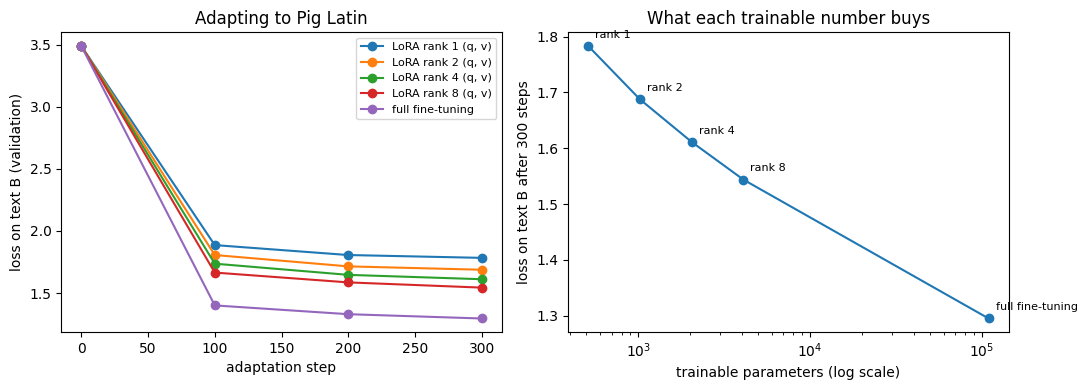

In [13]:
def show(names):
    print(f"{'run':26s} {'trainable':>9s} {'share':>7s} {'text B':>7s} {'gap closed':>10s} {'text A':>7s}")
    print(f"{'pretrained, not adapted':26s} {0:>9,} {0:>7.2%} {base_B:>7.3f} {0:>10.0%} {base_A:>7.3f}")
    full_B = results["full fine-tuning"]["B"]
    for name in names:
        r = results[name]
        closed = (base_B - r["B"]) / (base_B - full_B)
        print(f"{name:26s} {r['trainable']:>9,} {r['trainable'] / hand_total:>7.2%} {r['B']:>7.3f} {closed:>10.0%} {r['A']:>7.3f}")


sweep = [f"LoRA rank {r} (q, v)" for r in (1, 2, 4, 8)] + ["full fine-tuning"]
show(sweep)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in sweep:
    steps, vals = zip(*results[name]["curve"])
    ax[0].plot(steps, vals, "o-", label=name)
ax[0].set_xlabel("adaptation step"); ax[0].set_ylabel("loss on text B (validation)"); ax[0].legend(fontsize=8)
ax[0].set_title("Adapting to Pig Latin")
xs = [results[n]["trainable"] for n in sweep]; ys = [results[n]["B"] for n in sweep]
ax[1].semilogx(xs, ys, "o-")
for n, x_, y_ in zip(sweep, xs, ys):
    ax[1].annotate(n.replace(" (q, v)", "").replace("LoRA ", ""), (x_, y_), textcoords="offset points", xytext=(5, 6), fontsize=8)
ax[1].set_xlabel("trainable parameters (log scale)"); ax[1].set_ylabel("loss on text B after 300 steps")
ax[1].set_title("What each trainable number buys")
plt.tight_layout(); plt.show()

### Why we see this

Three things to read off, in the order an engineer would.

1. **The first few numbers do most of the work.** Rank 1 trains 512 numbers, under half a percent of the
   model, and closes the larger part of the gap. Each doubling of rank after that buys less than the one
   before.
2. **Rank is a dial, and here it does not reach the top.** The loss falls at every doubling, and at rank 8 it
   is still well short of full fine-tuning. On this task, in this small model, LoRA on two matrices per block
   **falls short at every rank we tried**, and worst at rank 1.
3. **Steps are not 27 times faster.** Compare the seconds. They wobble with whatever else your machine is
   doing, and they are of the same order for every run. The rank-8 run trains 27 times fewer numbers than
   full fine-tuning; on a model this small, on a CPU, it may not be measurably quicker at all. Every step
   still pushes the data through the whole frozen model and the error back through it. What the adapter
   skips is the gradient and the optimiser update for the frozen weights, which is a saving in memory more
   than in time.

Why the shortfall? Two reasons specific to this lab, both worth knowing. Pig Latin is a long way from the
pretraining text: every word's spelling changes, which is more than a change of topic or tone. And TinyGPT is
64 wide, so there is little spare room in it. Published results on large models and nearer tasks are much
kinder to LoRA than this table. The honest summary is the one in the chapter: **the further the task is from
pretraining, the more rank (or the more of the model) you need.**

---
## Step 14 - Is it the rank, or where the adapters are?

Two more runs settle what is holding LoRA back.

* **Rank 64 on query and value only.** Rank 64 on a 64 × 64 matrix is no restriction at all: A·B can be any
  matrix. This run asks what you get if those four matrices can change freely and nothing else can.
* **Rank 8 on all six linear layers of each block:** query, key, value, output, and both feed-forward
  layers. Hand count: four 64 → 64 layers at 128·r each, plus 64 → 256 and 256 → 64 at 320·r each, is
  1,152·r per block.

> **Predict:** which of the two gets closer to full fine-tuning: unlimited rank in two places, or rank 8
> everywhere?

In [14]:
keras.utils.set_random_seed(SEED + 64)
m = load_base(build_tinygpt(V, rank=64), base)
assert count_weights(m.trainable_weights) == 512 * 64
curve, seconds = adapt(m, LORA_LR)
record("LoRA rank 64 (q, v)", m, curve, seconds)

ALL_SIX = ("q", "k", "v", "o", "ff_wide", "ff_narrow")
keras.utils.set_random_seed(SEED + 6)
lora_all = load_base(build_tinygpt(V, rank=8, targets=ALL_SIX), base)
assert count_weights(lora_all.trainable_weights) == 2 * 1152 * 8 == 18_432
curve, seconds = adapt(lora_all, LORA_LR)
record("LoRA rank 8 (all six)", lora_all, curve, seconds)
print()
show(["LoRA rank 8 (q, v)", "LoRA rank 64 (q, v)", "LoRA rank 8 (all six)", "full fine-tuning"])

LoRA rank 64 (q, v)        trainable  32,768  text B 1.452  text A 3.316  [32 s]


LoRA rank 8 (all six)      trainable  18,432  text B 1.341  text A 3.406  [39 s]

run                        trainable   share  text B gap closed  text A
pretrained, not adapted            0   0.00%   3.489         0%   1.560
LoRA rank 8 (q, v)             4,096   3.75%   1.544        89%   3.305
LoRA rank 64 (q, v)           32,768  30.00%   1.452        93%   3.316
LoRA rank 8 (all six)         18,432  16.88%   1.341        98%   3.406
full fine-tuning             109,223 100.00%   1.295       100%   3.490


### Why we see this

Unlimited rank on the query and value matrices improves only a little on rank 8 there, while rank 8 spread
over every linear layer does clearly better, with fewer trainable numbers than the rank-64 run, and lands
close to full fine-tuning. So the ceiling in
Step 13 was mostly **placement**, not rank: part of what Pig Latin needs has to be learnt in layers that the
first recipe left frozen (the feed-forward layers, where much of a model's knowledge of spelling lives).

This is why "adapt all the linear layers at a modest rank" has become a common default, in place of the
original paper's query-and-value recipe. When an adapter stalls, try more places before more rank.

---
## Step 15 - Merge: pour the adapter into the weights

After training, `x @ W + (alpha / r) · x @ A @ B` is the same as `x @ (W + (alpha / r) · A @ B)`. So compute
the new matrix once, put it in an ordinary `Dense`, and throw the adapter away. The merged model has the
architecture of the pretrained one: no extra layers, no extra work per token.

> **Predict:** the parameter count of the merged model. And the largest difference between its outputs and
> the unmerged model's.

In [15]:
def merge(model):
    """A plain TinyGPT whose weights are the frozen ones with every adapter added in."""
    merged = build_tinygpt(V)
    for layer in merged.layers:
        if not layer.weights:
            continue
        source = model.get_layer(layer.name)
        if isinstance(source, LoRADense):
            W = source.kernel.numpy() + source.scale * source.lora_a.numpy() @ source.lora_b.numpy()
            layer.set_weights([W, source.bias.numpy()])
        else:
            layer.set_weights(source.get_weights())
    return merged


merged = merge(lora8)
merged.compile(loss=loss_fn)
diff = np.abs(merged.predict(xb_val[:256], verbose=0) - lora8.predict(xb_val[:256], verbose=0)).max()
print(f"with adapters: {lora8.count_params():,} numbers in the model   merged: {merged.count_params():,}")
print(f"largest difference in the logits: {diff:.2e}")
print(f"loss on text B: with adapters {results['LoRA rank 8 (q, v)']['B']:.4f}   merged {merged.evaluate(xb_val, yb_val, batch_size=250, verbose=0):.4f}")
assert merged.count_params() == hand_total and diff < 1e-4

with adapters: 113,319 numbers in the model   merged: 109,223
largest difference in the logits: 1.72e-05


loss on text B: with adapters 1.5437   merged 1.5437


### Why we see this

The merged model is 109,223 numbers again, and its outputs agree with the adapter model's to within a few
hundred-thousandths (the remainder is float32 rounding: adding two products is not bit-identical to
multiplying by a sum). At serving time a merged LoRA model costs exactly what the pretrained model costs.

The price of merging is that the adapter is no longer separate. You cannot unplug it, and if you go on
training the merged model you are doing full fine-tuning.

---
## Step 16 - Unplug it, and weigh it

The other way to use an adapter is to keep it apart from the base: one copy of the big model, and a small
file per task. `get_adapter` pulls the trained pairs out; setting B to zero unplugs them.

> **Predict:** with the adapter unplugged, what is the loss on text A? Compare with Step 5. And how many
> bytes is the rank-8 adapter in float32, against the whole model?

In [16]:
def get_adapter(model):
    return {layer.name: (layer.lora_a.numpy(), layer.lora_b.numpy()) for layer in lora_layers(model)}


def set_adapter(model, adapter):
    for layer in lora_layers(model):
        a_, b_ = adapter[layer.name]
        layer.lora_a.assign(a_); layer.lora_b.assign(b_)


pig_adapter = get_adapter(lora8)
unplugged = {name: (a_, np.zeros_like(b_)) for name, (a_, b_) in pig_adapter.items()}


def both_losses(model):
    return (model.evaluate(xa_val, ya_val, batch_size=250, verbose=0), model.evaluate(xb_val, yb_val, batch_size=250, verbose=0))


on = both_losses(lora8)
set_adapter(lora8, unplugged); off = both_losses(lora8)
set_adapter(lora8, pig_adapter); back = both_losses(lora8)
print(f"{'':22s} {'text A':>7s} {'text B':>7s}")
print(f"{'adapter plugged in':22s} {on[0]:>7.3f} {on[1]:>7.3f}")
print(f"{'adapter unplugged':22s} {off[0]:>7.3f} {off[1]:>7.3f}   (pretrained: {base_A:.3f}, {base_B:.3f})")
print(f"{'plugged in again':22s} {back[0]:>7.3f} {back[1]:>7.3f}")
print(f"{'full fine-tuning':22s} {results['full fine-tuning']['A']:>7.3f} {results['full fine-tuning']['B']:>7.3f}   (its English is gone unless you kept a copy)")
assert abs(off[0] - base_A) < 1e-6 and abs(back[1] - on[1]) < 1e-6

adapter_bytes = 4 * sum(a_.size + b_.size for a_, b_ in pig_adapter.values())
print(f"\nrank-8 adapter: {adapter_bytes:,} bytes   whole model: {4 * hand_total:,} bytes   ({4 * hand_total / adapter_bytes:.0f} times more)")
print(f"ten tasks: ten full copies {10 * 4 * hand_total:,} bytes;  one base + ten adapters {4 * hand_total + 10 * adapter_bytes:,} bytes")

                        text A  text B
adapter plugged in       3.305   1.544
adapter unplugged        1.560   3.489   (pretrained: 1.560, 3.489)
plugged in again         3.305   1.544
full fine-tuning         3.490   1.295   (its English is gone unless you kept a copy)

rank-8 adapter: 16,384 bytes   whole model: 436,892 bytes   (27 times more)
ten tasks: ten full copies 4,368,920 bytes;  one base + ten adapters 600,732 bytes


### Why we see this

Unplugged, the model is the pretrained model to the last digit: its English is back, because it never went
anywhere. Plug the adapter in again and the Pig Latin returns. One base model can serve many tasks this way,
each task being a small file, loaded on request.

A fully fine-tuned model has no such switch. Its loss on text A is ruined in the same way, and the only route
back is a second full copy of the weights.

---
## Step 17 - Why can a small rank work at all? Look at what full fine-tuning changed

LoRA bets that the change a task needs is **simple**: that it mostly lies along a few directions. We can
test the bet on the full fine-tune of Step 12, which was free to change every matrix any way it liked.
Subtract the pretrained matrix from the fine-tuned one, and take the singular values of the difference: they
measure how much of the change lies along each of its 64 directions, largest first.

For comparison, a matrix of pure random numbers spreads its size over all 64 directions about as evenly as a
matrix can.

> **Predict:** what share of the change lies in the top 8 of 64 directions? If the change had no structure
> at all you would expect about what the random matrix shows.

weight change of   size vs W  top 1  top 4  top 8  directions for 90%
block1_q                0.10    22%    49%    67%                  19
block1_k                0.08    16%    45%    68%                  18
block1_v                0.09    15%    41%    62%                  20
block1_o                0.11    10%    30%    50%                  27
block2_q                0.19    11%    33%    54%                  25
block2_k                0.16    12%    35%    54%                  24
block2_v                0.16    12%    34%    55%                  24
block2_o                0.17    12%    36%    54%                  25
random 64 x 64                                38%                  33   (mean of 20)

top-8 share over the eight attention matrices: 50% to 68%, mean 58%
the rank-8 adapter's own change to block1_q: singular values 7 to 10 = [0.662 0.425 0.    0.   ]


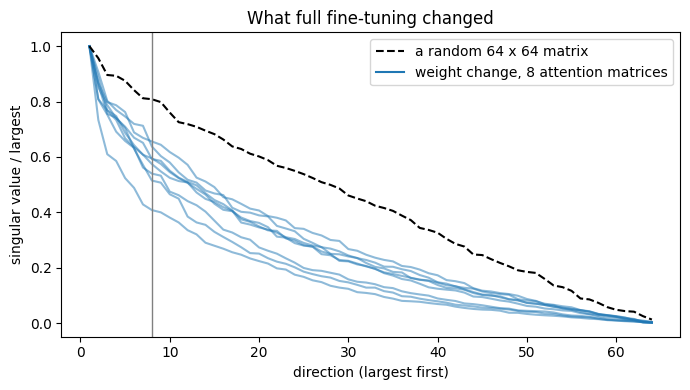

In [17]:
def top_share(M, k):
    s = np.linalg.svd(M, compute_uv=False)
    energy = s ** 2 / np.sum(s ** 2)                      # share of the squared size along each direction
    return float(energy[:k].sum()), int(np.searchsorted(np.cumsum(energy), 0.9) + 1), s


print(f"{'weight change of':18s} {'size vs W':>9s} {'top 1':>6s} {'top 4':>6s} {'top 8':>6s} {'directions for 90%':>19s}")
spectra, top8 = {}, []
for b_ in (1, 2):
    for kind in ("q", "k", "v", "o"):
        name = f"block{b_}_{kind}"
        W0 = base.get_layer(name).get_weights()[0]
        delta = full.get_layer(name).get_weights()[0] - W0
        s1, _, _ = top_share(delta, 1); s4, _, _ = top_share(delta, 4); s8, n90, s = top_share(delta, 8)
        spectra[name] = s; top8.append(s8)
        print(f"{name:18s} {np.linalg.norm(delta) / np.linalg.norm(W0):>9.2f} {s1:>6.0%} {s4:>6.0%} {s8:>6.0%} {n90:>19d}")
g = np.random.default_rng(3)
rand = [top_share(g.normal(size=(64, 64)), 8) for _ in range(20)]
rand_top8, rand_n90 = np.mean([r[0] for r in rand]), np.mean([r[1] for r in rand])
print(f"{'random 64 x 64':18s} {'':>9s} {'':>6s} {'':>6s} {rand_top8:>6.0%} {rand_n90:>19.0f}   (mean of 20)")
print(f"\ntop-8 share over the eight attention matrices: {min(top8):.0%} to {max(top8):.0%}, mean {np.mean(top8):.0%}")

s_lora = np.linalg.svd(pig_adapter["block1_q"][0] @ pig_adapter["block1_q"][1], compute_uv=False)
print("the rank-8 adapter's own change to block1_q: singular values 7 to 10 =", s_lora[6:10].round(5))

plt.figure(figsize=(7, 4))
for name, s in spectra.items():
    plt.plot(np.arange(1, 65), s / s[0], color="tab:blue", alpha=0.5)
plt.plot(np.arange(1, 65), rand[0][2] / rand[0][2][0], "k--", label="a random 64 x 64 matrix")
plt.plot([], [], color="tab:blue", label="weight change, 8 attention matrices")
plt.axvline(8, color="grey", linewidth=1)
plt.xlabel("direction (largest first)"); plt.ylabel("singular value / largest")
plt.title("What full fine-tuning changed"); plt.legend(); plt.tight_layout(); plt.show()

### Why we see this

The change is **lopsided**: its top 8 directions hold between a half and two thirds of it, against a little
over a third for a matrix with no structure, and it reaches 90% in clearly fewer directions. So the bet has something in
it even here. A rank-8 adapter can reproduce the larger part of what full fine-tuning chose to do to these
matrices.

It is also **not** a clean low-rank change: the curve does not drop to nothing after a handful of directions,
and the tail holds a real share. That matches Steps 13 and 14, where rank 8 helped a lot and did not reach
full fine-tuning. On large pretrained models and tasks nearer their pretraining, studies report weight
changes concentrated in far fewer directions relative to the width. Treat "the update a task needs has low
rank" as a well-supported working hypothesis, strongest when the model is big and the task is close.

The last printed line is the adapter's own change: singular values 9 and 10 are zero to rounding. A rank-8
adapter has exactly 8 directions to spend.

---
## Step 18 - The same arithmetic at full size

GPT-2 small (2019) is 768 wide with 12 blocks and 124,439,808 parameters. Put rank-8 adapters on the query
and value projections of every block.

> **Predict:** the trainable share. Bigger or smaller than TinyGPT's 3.75%, and by roughly how much?

In [18]:
d_big, r = 768, 8
one_matrix = d_big * d_big
one_adapter = r * (d_big + d_big)
gpt2_total = 124_439_808
gpt2_adapter = 12 * 2 * one_adapter
print(f"one 768 x 768 matrix: {one_matrix:,}   rank-8 adapter on it: {one_adapter:,}   ({one_adapter / one_matrix:.2%})")
print(f"GPT-2 small, rank 8 on q and v of 12 blocks: {gpt2_adapter:,} trainable of {gpt2_total:,}  ({gpt2_adapter / gpt2_total:.3%})")
print(f"as float32 files: adapter {gpt2_adapter * 4 / 1e6:.2f} MB, model {gpt2_total * 4 / 1e6:.0f} MB")
print(f"TinyGPT, same recipe: {hand_train:,} of {hand_total:,}  ({hand_train / hand_total:.2%})")
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

one 768 x 768 matrix: 589,824   rank-8 adapter on it: 12,288   (2.08%)
GPT-2 small, rank 8 on q and v of 12 blocks: 294,912 trainable of 124,439,808  (0.237%)
as float32 files: adapter 1.18 MB, model 498 MB
TinyGPT, same recipe: 4,096 of 109,223  (3.75%)

whole notebook: 439 s


### Why we see this

The same recipe trains about a quarter of one percent of GPT-2 small, where it trained 3.75% of TinyGPT. The
adapter grows in step with the width; the model grows with its square. That is the whole economic case: in a
model wide enough to be expensive, the adapter is small enough to be nearly free to store and to ship.

What the arithmetic does not tell you is how well rank 8 would work there. That depends on the task, and it
has to be measured, as Steps 11 to 14 measured it here.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 14: `targets=("ff_wide", "ff_narrow")` at rank 8 | Trainable count (hand first). Better or worse than rank 8 on q and v? | |
| 2 | Step 10: `LORA_LR = 1e-3` (the full fine-tuning rate) | Does the adapter still get there in 300 steps? | |
| 3 | Step 11: `build_tinygpt(V, rank=rank, alpha=8)` for every rank | The factor is now 8 at rank 1 and 1 at rank 8. Which ranks change, and which way? | |
| 4 | Step 10: `ADAPT_STEPS = 900` | Does the gap between rank 8 and full fine-tuning close, hold or widen? | |
| 5 | Step 7: `lora_a` initialised with `"zeros"` as well | What is the loss after 300 steps? Why? | |
| 6 | Step 8: delete the line `layer.trainable = False` in `build_tinygpt` | Trainable count? Does the Step 10 check on frozen kernels still pass? | |
| 7 | Step 2: make text B plain reviews from 2,700 on (no Pig Latin) | How much is there to gain? What does rank 1 do now? | |
| 8 | Step 15: merge `lora_all` instead of `lora8` | Parameter count of the merged model? Largest difference? | |

---
## Exercises

1. **Two adapters, one base.** Make a text C (for example every word reversed) and train a second rank-8
   adapter for it on a fresh `build_tinygpt(V, rank=8)`. Then serve both tasks from one model by swapping
   adapters with `set_adapter`, and check each against its own validation text.
2. **Add two adapters together.** With the adapters of Exercise 1, merge both into one model
   (W + A₁B₁ + A₂B₂). Measure the loss on text B and on text C. Is the result good at both, one or neither?
3. **Dropout on the adapter.** Give `LoRADense` a `dropout` argument applied to `x` on the adapter path only.
   Shrink the adaptation set to 20 reviews, and compare validation loss with and without it.
4. **BitFit.** Freeze everything except the bias vectors (and nothing else). Count the trainable numbers by
   hand first, then run `adapt`. Where does it land in the Step 13 table?
5. **Truncate the full fine-tune.** For each attention matrix take the full fine-tune's weight change, keep
   only its top r singular directions (`np.linalg.svd`), add that to the pretrained matrix, and measure the
   loss on text B for r = 1, 2, 4, 8, 16, 64. Compare with the LoRA runs of the same rank.
6. **From nothing.** Train a fresh TinyGPT on text B alone for 300 steps. Where does it land against the
   adapted models? What did pretraining on English buy for Pig Latin?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| LoRA | freeze W; learn a change A·B; compute `x @ W + (alpha / r) · x @ A @ B` |
| Shapes (Keras layout) | A: (d_in, r), small random; B: (r, d_out), zeros |
| Trainable numbers per adapted layer | r · (d_in + d_out) |
| 768 × 768 at rank 8 | 12,288 against 589,824 (2.08%) |
| Zero start | B = 0 means the adapted model equals the pretrained one exactly, before training |
| Both zero | nothing ever trains; both random: the model is damaged before step 1 |
| Rank | the number of directions the change can push a layer's output along; a capacity dial |
| alpha / r | a fixed loudness factor; change r without it and the effective step size changes |
| Freeze check | assert trainable == what you counted by hand, frozen == the pretrained count |
| TinyGPT, rank r on q and v | 512·r trainable; rank 8 = 4,096 (3.75% of 109,223) |
| TinyGPT, rank r on all six linear layers | 2,304·r trainable; rank 8 = 18,432 |
| Merge | W ← W + (alpha / r) · A·B; same outputs, no extra cost at inference, no longer removable |
| Unplug or swap | keep (A, B) per task in a small file; the base model is never touched |
| Speed | training steps are not many times faster: forward and backward still cross the whole model |
| When it stalls | add adapters in more places before raising the rank; far tasks may need full fine-tuning |
| GPT-2 small, rank 8 on q and v | 294,912 trainable of 124,439,808 (0.237%), about 1.18 MB |